# Dimensions³ — Reproducible Flood Evidence Demo

**Study area:** Jebel Ali, Dubai, United Arab Emirates  
**Theme:** Climate-induced Disasters

This notebook reproduces the headline result of the Dimensions³ proof of concept using a small processed sample committed to the repository.

The sample combines:

- Sentinel-1 radar candidate-water evidence
- Sentinel-2 multispectral water-change evidence
- Landsat 9 water-change evidence
- NASA POWER rainfall information
- Official reports and public supporting evidence

The notebook produces a transparent preliminary flood-evidence score and an example output figure without downloading the full satellite products.

> The result is a preliminary screening indicator, not a validated flood-extent map or formal accuracy measurement.

In [1]:
# ============================================================
# CELL 1 — LOCATE OR DOWNLOAD THE PROJECT REPOSITORY
# ============================================================

from pathlib import Path
import subprocess
import os

print("=" * 60)
print("DIMENSIONS³ REPRODUCIBLE DEMO — SETUP")
print("=" * 60)

REPOSITORY_URL = (
    "https://github.com/vfatimaalkaabi/"
    "dimensions3-flood-poc.git"
)

REPOSITORY_NAME = "dimensions3-flood-poc"
SAMPLE_RELATIVE_PATH = Path(
    "data/sample_input/dimensions3_sample_input.npz"
)

# Possible locations when running locally or in Google Colab
candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/content") / REPOSITORY_NAME
]

repository_root = None

# Look for the sample file in an existing repository
for candidate in candidate_roots:
    if (candidate / SAMPLE_RELATIVE_PATH).exists():
        repository_root = candidate.resolve()
        break

# If not found, download the public GitHub repository
if repository_root is None:
    colab_repository = Path("/content") / REPOSITORY_NAME

    if colab_repository.exists():
        print("Existing Colab repository found. Updating it...")
        subprocess.run(
            [
                "git",
                "-C",
                str(colab_repository),
                "pull",
                "--ff-only"
            ],
            check=True
        )
    else:
        print("Downloading the public GitHub repository...")
        subprocess.run(
            [
                "git",
                "clone",
                REPOSITORY_URL,
                str(colab_repository)
            ],
            check=True
        )

    repository_root = colab_repository.resolve()

sample_path = repository_root / SAMPLE_RELATIVE_PATH
results_folder = repository_root / "results"

if not sample_path.exists():
    raise FileNotFoundError(
        "Sample input was not found at:\n"
        f"{sample_path}\n\n"
        "Confirm that dimensions3_sample_input.npz "
        "was committed to data/sample_input/."
    )

results_folder.mkdir(parents=True, exist_ok=True)

print("\nSetup complete.")
print("Repository root:", repository_root)
print("Sample input:", sample_path)
print("Results folder:", results_folder)
print("=" * 60)

DIMENSIONS³ REPRODUCIBLE DEMO — SETUP

Setup complete.
Repository root: /content/dimensions3-flood-poc
Sample input: /content/dimensions3-flood-poc/data/sample_input/dimensions3_sample_input.npz
Results folder: /content/dimensions3-flood-poc/results


In [2]:
# ============================================================
# CELL 2 — LOAD AND INSPECT THE SAMPLE INPUT
# ============================================================

import numpy as np

print("=" * 60)
print("LOADING SAMPLE INPUT")
print("=" * 60)

sample = np.load(
    sample_path,
    allow_pickle=False
)

# Load satellite evidence masks
sentinel1_mask = sample[
    "sentinel1_candidate_mask"
].astype(bool)

sentinel2_mask = sample[
    "sentinel2_candidate_mask"
].astype(bool)

landsat9_mask = sample[
    "landsat9_candidate_mask"
].astype(bool)

valid_land_mask = sample[
    "valid_land_mask"
].astype(bool)

# Load supporting evidence
peak_rainfall_mm = float(
    sample["peak_rainfall_mm"]
)

official_report_count = int(
    sample["official_report_count"]
)

public_evidence_count = int(
    sample["public_evidence_count"]
)

# Load descriptive metadata
study_area = str(sample["study_area"])
event_date = str(sample["event_date"])
source_description = str(
    sample["source_description"]
)

print("\nStudy area:", study_area)
print("Event date:", event_date)
print("Sources:", source_description)

print("\nSatellite mask shapes:")
print("Sentinel-1:", sentinel1_mask.shape)
print("Sentinel-2:", sentinel2_mask.shape)
print("Landsat 9 :", landsat9_mask.shape)
print("Valid land:", valid_land_mask.shape)

print("\nSupporting evidence:")
print("Peak rainfall:", peak_rainfall_mm, "mm")
print("Official reports:", official_report_count)
print("Public evidence records:", public_evidence_count)

print("\nSample input loaded successfully.")
print("=" * 60)

LOADING SAMPLE INPUT

Study area: Jebel Ali, Dubai, United Arab Emirates
Event date: 2024-04-16
Sources: Processed Sentinel-1, Sentinel-2, Landsat 9, NASA POWER rainfall, and supporting evidence

Satellite mask shapes:
Sentinel-1: (374, 341)
Sentinel-2: (374, 341)
Landsat 9 : (374, 341)
Valid land: (374, 341)

Supporting evidence:
Peak rainfall: 53.38999938964844 mm
Official reports: 6
Public evidence records: 3

Sample input loaded successfully.


In [3]:
# ============================================================
# CELL 3 — REPRODUCE THE MULTI-SOURCE EVIDENCE SCORE
# ============================================================

print("=" * 60)
print("REPRODUCING MULTI-SOURCE FLOOD SCREENING")
print("=" * 60)

# Count how many satellite sources identify each pixel
sensor_votes = (
    sentinel1_mask.astype(np.uint8)
    + sentinel2_mask.astype(np.uint8)
    + landsat9_mask.astype(np.uint8)
)

# A candidate requires agreement from at least two sensors
# and must fall inside the valid land-analysis area.
high_agreement_mask = (
    (sensor_votes >= 2)
    & valid_land_mask
)

valid_pixel_count = int(
    valid_land_mask.sum()
)

candidate_pixel_count = int(
    high_agreement_mask.sum()
)

if valid_pixel_count == 0:
    raise ValueError(
        "The valid-land mask contains no valid pixels."
    )

candidate_percentage = (
    candidate_pixel_count
    / valid_pixel_count
    * 100
)

# ------------------------------------------------------------
# Convert evidence into normalized support values
# ------------------------------------------------------------

# Full spatial support is reached at 5% candidate coverage.
spatial_support = min(
    candidate_percentage / 5.0,
    1.0
)

# Full rainfall support is reached at 50 mm.
rainfall_support = min(
    peak_rainfall_mm / 50.0,
    1.0
)

total_evidence_records = (
    official_report_count
    + public_evidence_count
)

# Six or more supporting records provide full support.
evidence_support = min(
    total_evidence_records / 6.0,
    1.0
)

# Transparent heuristic weighting:
# 50% spatial evidence
# 30% rainfall evidence
# 20% report/public evidence
combined_score = (
    0.50 * spatial_support
    + 0.30 * rainfall_support
    + 0.20 * evidence_support
)

# Assign the preliminary screening label
if combined_score >= 0.70:
    screening_label = "HIGH"
elif combined_score >= 0.40:
    screening_label = "MEDIUM"
else:
    screening_label = "LOW"

print("\nSpatial evidence")
print("Valid pixels:", valid_pixel_count)
print("High-agreement pixels:", candidate_pixel_count)
print(
    "High-agreement candidate area:",
    round(candidate_percentage, 2),
    "%"
)

print("\nSupporting evidence")
print(
    "Peak rainfall:",
    round(peak_rainfall_mm, 2),
    "mm"
)
print(
    "Total evidence records:",
    total_evidence_records
)

print("\nNormalized support")
print(
    "Spatial support:",
    round(spatial_support, 3)
)
print(
    "Rainfall support:",
    round(rainfall_support, 3)
)
print(
    "Evidence support:",
    round(evidence_support, 3)
)

print("\n" + "=" * 60)
print("REPRODUCED HEADLINE RESULT")
print("=" * 60)
print("Screening label:", screening_label)
print(
    "Combined evidence score:",
    round(combined_score, 3)
)
print(
    "Candidate area:",
    round(candidate_percentage, 2),
    "%"
)
print("=" * 60)

REPRODUCING MULTI-SOURCE FLOOD SCREENING

Spatial evidence
Valid pixels: 118327
High-agreement pixels: 873
High-agreement candidate area: 0.74 %

Supporting evidence
Peak rainfall: 53.39 mm
Total evidence records: 9

Normalized support
Spatial support: 0.148
Rainfall support: 1.0
Evidence support: 1.0

REPRODUCED HEADLINE RESULT
Screening label: MEDIUM
Combined evidence score: 0.574
Candidate area: 0.74 %


CREATING REPRODUCIBLE OUTPUT


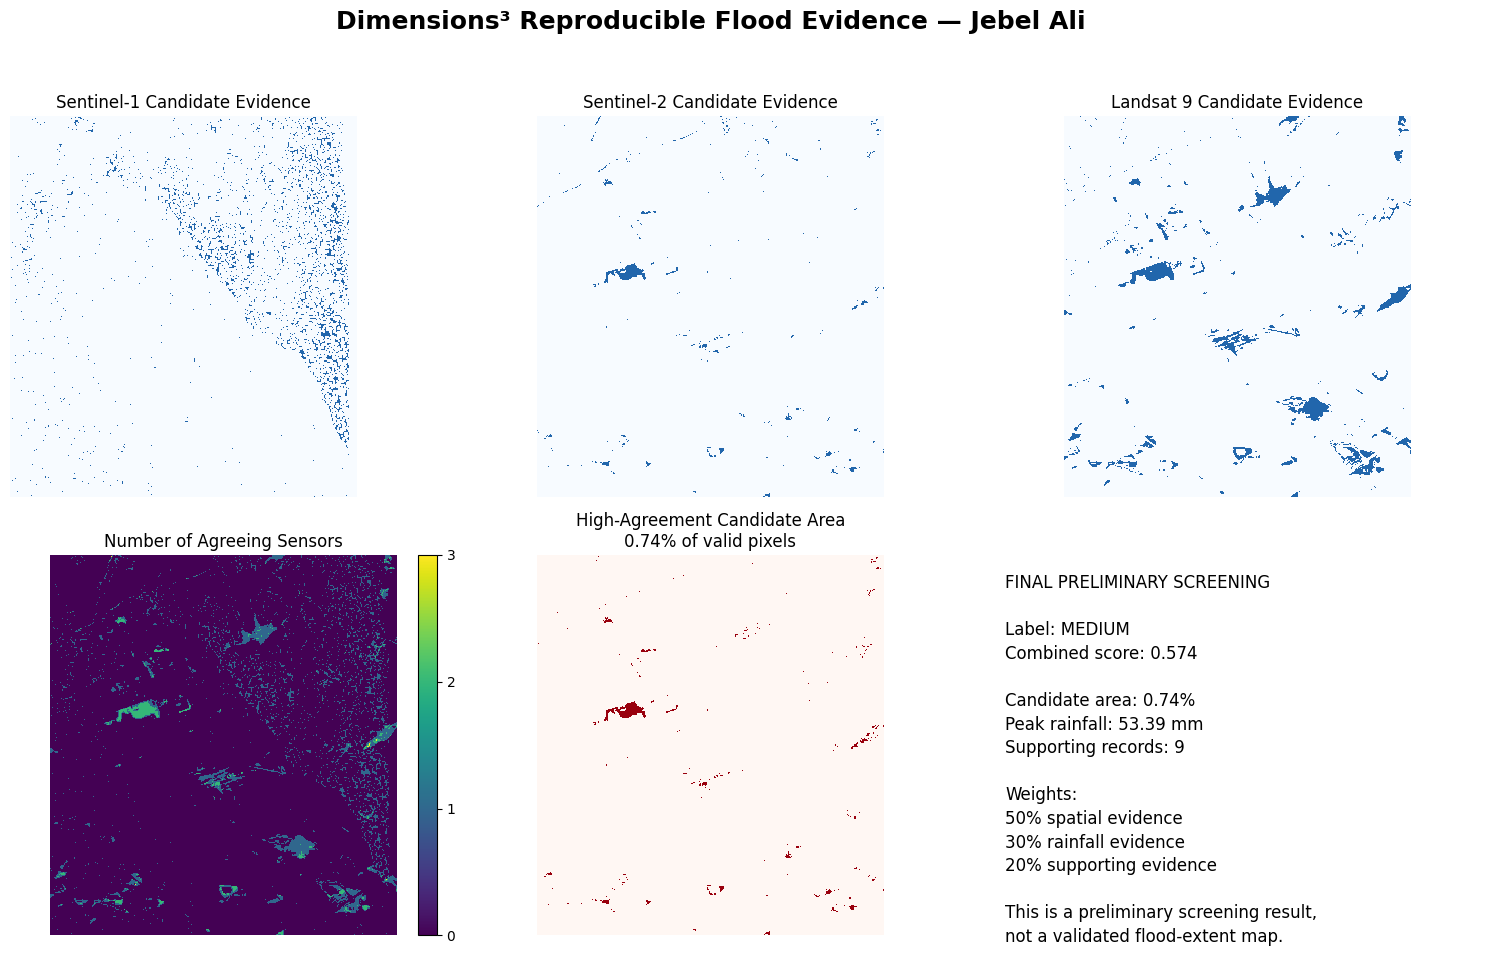


Reproducible analysis complete.
Figure saved: /content/dimensions3-flood-poc/results/reproducible_flood_evidence_result.png
Summary saved: /content/dimensions3-flood-poc/results/reproducible_flood_evidence_summary.json


In [4]:
# ============================================================
# CELL 4 — CREATE AND SAVE THE REPRODUCIBLE OUTPUT
# ============================================================

import json
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

print("=" * 60)
print("CREATING REPRODUCIBLE OUTPUT")
print("=" * 60)

figure_path = (
    results_folder
    / "reproducible_flood_evidence_result.png"
)

summary_path = (
    results_folder
    / "reproducible_flood_evidence_summary.json"
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

fig.suptitle(
    "Dimensions³ Reproducible Flood Evidence — Jebel Ali",
    fontsize=18,
    fontweight="bold"
)

mask_cmap = ListedColormap(
    ["#f7fbff", "#2166ac"]
)

final_cmap = ListedColormap(
    ["#fff7f3", "#99000d"]
)

# Sentinel-1
axes[0, 0].imshow(
    sentinel1_mask,
    cmap=mask_cmap,
    interpolation="nearest"
)
axes[0, 0].set_title("Sentinel-1 Candidate Evidence")
axes[0, 0].axis("off")

# Sentinel-2
axes[0, 1].imshow(
    sentinel2_mask,
    cmap=mask_cmap,
    interpolation="nearest"
)
axes[0, 1].set_title("Sentinel-2 Candidate Evidence")
axes[0, 1].axis("off")

# Landsat 9
axes[0, 2].imshow(
    landsat9_mask,
    cmap=mask_cmap,
    interpolation="nearest"
)
axes[0, 2].set_title("Landsat 9 Candidate Evidence")
axes[0, 2].axis("off")

# Sensor agreement
agreement_image = axes[1, 0].imshow(
    sensor_votes,
    cmap="viridis",
    vmin=0,
    vmax=3,
    interpolation="nearest"
)
axes[1, 0].set_title("Number of Agreeing Sensors")
axes[1, 0].axis("off")

agreement_colorbar = fig.colorbar(
    agreement_image,
    ax=axes[1, 0],
    fraction=0.046,
    pad=0.04
)
agreement_colorbar.set_ticks([0, 1, 2, 3])

# Final high-agreement mask
axes[1, 1].imshow(
    high_agreement_mask,
    cmap=final_cmap,
    interpolation="nearest"
)
axes[1, 1].set_title(
    "High-Agreement Candidate Area\n"
    f"{candidate_percentage:.2f}% of valid pixels"
)
axes[1, 1].axis("off")

# Final result text
axes[1, 2].axis("off")

result_text = (
    "FINAL PRELIMINARY SCREENING\n\n"
    f"Label: {screening_label}\n"
    f"Combined score: {combined_score:.3f}\n\n"
    f"Candidate area: {candidate_percentage:.2f}%\n"
    f"Peak rainfall: {peak_rainfall_mm:.2f} mm\n"
    f"Supporting records: {total_evidence_records}\n\n"
    "Weights:\n"
    "50% spatial evidence\n"
    "30% rainfall evidence\n"
    "20% supporting evidence\n\n"
    "This is a preliminary screening result,\n"
    "not a validated flood-extent map."
)

axes[1, 2].text(
    0.05,
    0.95,
    result_text,
    va="top",
    fontsize=12,
    linespacing=1.4
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save a machine-readable result
summary = {
    "project": "Dimensions³",
    "study_area": study_area,
    "event_date": event_date,
    "screening_label": screening_label,
    "combined_evidence_score": round(
        combined_score,
        3
    ),
    "candidate_area_percent": round(
        candidate_percentage,
        2
    ),
    "candidate_pixel_count": candidate_pixel_count,
    "valid_pixel_count": valid_pixel_count,
    "peak_rainfall_mm": round(
        peak_rainfall_mm,
        2
    ),
    "official_report_count": official_report_count,
    "public_evidence_count": public_evidence_count,
    "total_evidence_records": total_evidence_records,
    "spatial_support": round(
        spatial_support,
        3
    ),
    "rainfall_support": round(
        rainfall_support,
        3
    ),
    "evidence_support": round(
        evidence_support,
        3
    ),
    "interpretation": (
        "Preliminary multi-source flood-related "
        "surface-change screening result."
    ),
    "limitation": (
        "This score is heuristic and is not a formal "
        "accuracy metric or validated flood-extent map."
    )
}

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as output_file:
    json.dump(
        summary,
        output_file,
        indent=2
    )

print("\nReproducible analysis complete.")
print("Figure saved:", figure_path)
print("Summary saved:", summary_path)
print("=" * 60)

In [5]:
# ============================================================
# CELL 5 — DOWNLOAD REPRODUCIBLE OUTPUTS
# ============================================================

from google.colab import files

print("Downloading reproducible figure...")
files.download(str(figure_path))

print("Downloading reproducible summary...")
files.download(str(summary_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from google.colab import files

files.download(
    str(
        results_folder
        / "reproducible_flood_evidence_result.png"
    )
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>